# Linear regression with Python

**STEP 1: Import packages that will be used**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

**STEP 2: Load data**

In [2]:
wine_df = pd.read_csv("Wine.csv")

# Display the first 5 rows of the DataFrame
print(wine_df.head(5))

# Display the last 3 tows of the DataFrame
print(wine_df.tail(3))

   Year   Price  WinterRain     AGST  HarvestRain  Age  FrancePop
0  1952  7.4950         600  17.1167          160   31  43183.569
1  1953  8.0393         690  16.7333           80   30  43495.030
2  1955  7.6858         502  17.1500          130   28  44217.857
3  1957  6.9845         420  16.1333          110   26  45152.252
4  1958  6.7772         582  16.4167          187   25  45653.805
    Year   Price  WinterRain     AGST  HarvestRain  Age  FrancePop
22  1976  7.1211         418  17.6500          247    7  54159.049
23  1977  6.2587         821  15.5833           87    6  54378.362
24  1978  7.1860         763  15.8167           51    5  54602.193


**STEP 4: Visualization of the data points**

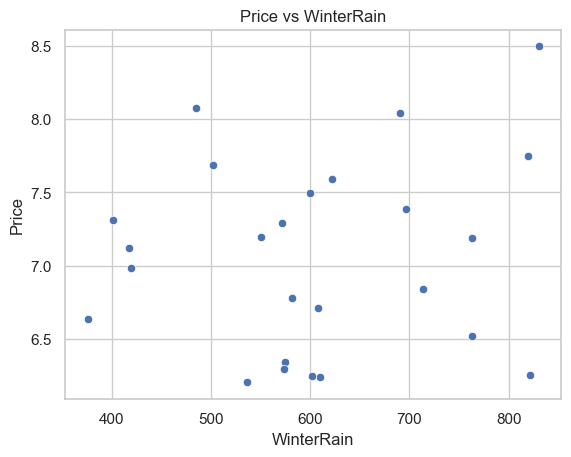

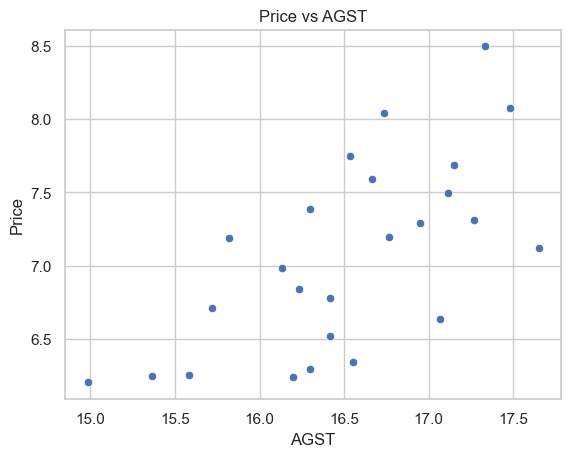

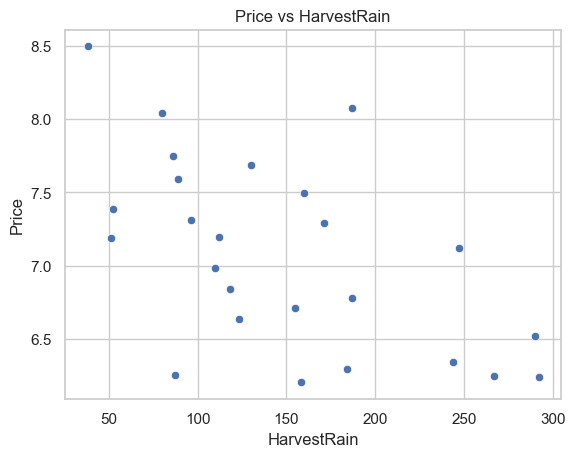

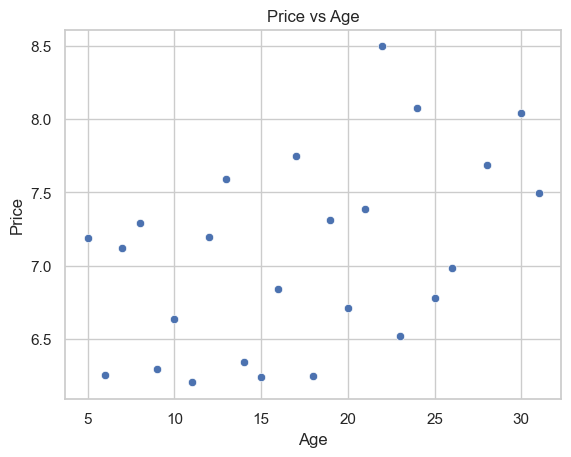

In [3]:
sns.set_theme(style="whitegrid")

# Create a scatter plot
sns.scatterplot(data = wine_df, x="WinterRain", y="Price")
plt.title("Price vs WinterRain")

plt.show()

# Create a scatter plot
sns.scatterplot(data = wine_df, x="AGST", y="Price")
plt.title("Price vs AGST")
plt.show()

# Create a scatter plot
sns.scatterplot(data = wine_df, x="HarvestRain", y="Price")
plt.title("Price vs HarvestRain")
plt.show()

# Create a scatter plt of Age and Price
sns.scatterplot(data = wine_df, x="Age", y="Price")
plt.title("Price vs Age")   
plt.show()

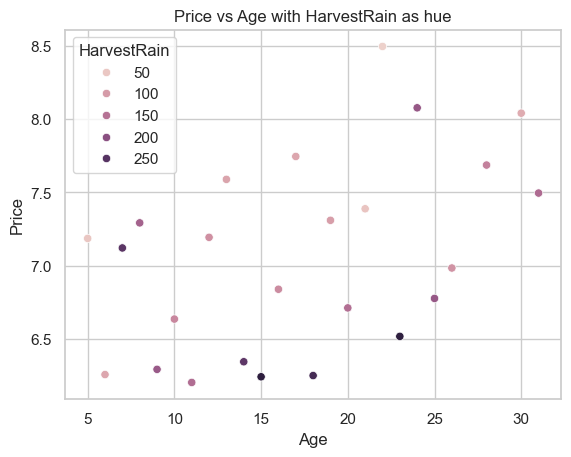

In [4]:
# Create a scatter plot of price and Age and use HarvestRain as hue
sns.scatterplot(data = wine_df, x="Age", y="Price", hue="HarvestRain")
plt.title("Price vs Age with HarvestRain as hue")   
plt.show()

* Winter rain won't affect the growing season of grapes, so it seems not correlated with the price.
* Before Harvest: Rain close to the harvest can be detrimental. It can cause the grapes to swell and burst, increasing the risk of mold and diluting the sugar concentration in the grapes, which affects the flavor and alcohol content of the wine.
* Averge Growing Season Temperature increases,and the Price of the wine increases.



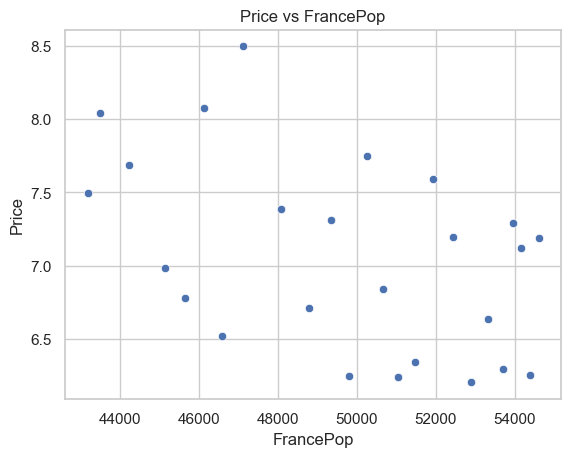

In [5]:
# Create a scatter plot of the FrancePop and Price
sns.scatterplot(data = wine_df, x="FrancePop", y="Price")
plt.title("Price vs FrancePop") 
plt.show()

The price of the wine can be influenced by several factors correlated with the France population. For example: Market size, Economies of Scale, Supply and Demand Dynamics, Customer preferences. Or simply it could refelect the association between population figures and time.

It's important to note that **correlation does not imply causation**. The relationship observed in the scatter plot does not necessarily mean that population growth causes changes in wine prices; both could be influenced by a third factor, or the observed relationship could be coincidental.

We can also explore the relationshipship btw other variables.

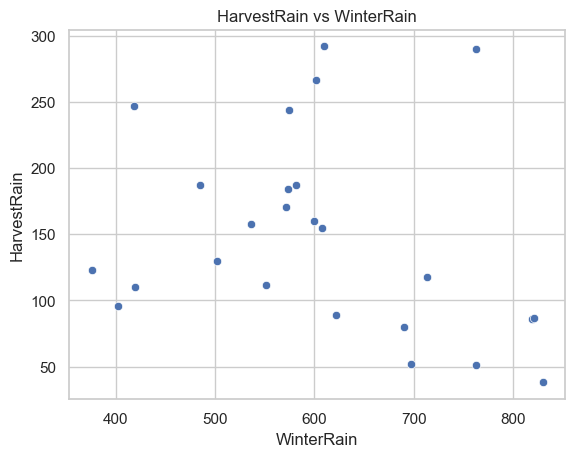

In [6]:
# Create a scatter plot btw WinterRain and HarvestRain
sns.scatterplot(data = wine_df, x="WinterRain", y="HarvestRain")
plt.title("HarvestRain vs WinterRain")
plt.xlabel("WinterRain")
plt.ylabel("HarvestRain")
plt.show()


#sns.pairplot(wine_df, diag_kind="kde")
#plt.show()

## Mini activity

Take 4 minutes to observe the data, create a new data visualization of your choice,

## Simple Regression with statmodels.


**STEP 5: Linear regression**

The primary goal of linear regression is to find a linear relationship between these variables.

1. quantifying such relationship.
2. predictive analysis.

In [7]:
import statsmodels.formula.api as smf

ols = Ordinary least square = Linear regression

We start by defining the regression model. The `ols` function from `statsmodels.formula.api (smf.ols)` is used to initialize our Ordinary Least Squares (OLS) regression.

Here, `Price` represents the dependent variable we aim to predict, and `AGST` represents the independent variable, the predictor, which in this context is the average temperature during the growing season.

These are specified in a formula string, similar to a regression equation, where `~` separates the dependent variable from the independent variable(s). The data argument is set to `wine_df`, which is our DataFrame that contains the relevant data.

In [8]:
# Get the collumns of our DataFrame
print(wine_df.columns)

Index(['Year', 'Price', 'WinterRain', 'AGST', 'HarvestRain', 'Age',
       'FrancePop'],
      dtype='object')


In [9]:
# Define the model as Dependent Variable ~ Independent Variables
model_1 = smf.ols(formula="Price ~  AGST", data=wine_df)



Once the model is defined, we proceed to fit it to our data. The ``fit()`` method calculates the best-fit line that minimizes the discrepancy between the actual and predicted values of our dependent variable (Price) across all observations in `wine_df`. The fit process involves finding the coefficients of the regression line that result in the lowest possible error.

The outcome of the `fit()` method is stored in `result_1`, which now contains the detailed results of our regression analysis, including the regression coefficients, statistical tests, and diagnostics that help us understand the relationship between wine prices and growing season temperatures.


In [10]:
### Train the model
result_1 = model_1.fit()

# Print the summary of the model
print(result_1.summary())   

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.435
Model:                            OLS   Adj. R-squared:                  0.410
Method:                 Least Squares   F-statistic:                     17.71
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           0.000335
Time:                        09:08:21   Log-Likelihood:                -17.070
No. Observations:                  25   AIC:                             38.14
Df Residuals:                      23   BIC:                             40.58
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.4178      2.494     -1.371      0.1

### Interpreting the results of OLS

When we perform a linear regression analysis, the output yields several statistical measures to evaluate the model's performance.

### (Optional) Saving predictions and erros to dataframe

In [11]:
result_1.predict()

array([7.45295742, 7.20946226, 7.47410606, 6.82840568, 7.0083914 ,
       7.68578299, 7.0083914 , 7.59051885, 6.9342759 , 6.56382539,
       7.54822157, 6.34154238, 7.0824434 , 6.89191511, 6.87076647,
       7.09304947, 7.16716498, 7.23067441, 6.09804722, 7.4212027 ,
       6.9342759 , 7.3470872 , 7.79165321, 6.47910381, 6.62733482])

In [12]:
# Get the coeeficient of the model  
result_1.params

Intercept   -3.417761
AGST         0.635094
dtype: float64

In [13]:
df_temp = wine_df.copy()

# Create a new column in the DataFrame
df_temp["yhat"] = result_1.predict()
df_temp.head()

,Year,Price,WinterRain,AGST,HarvestRain,Age,FrancePop,yhat
0,1952,7.4950,600,17.1167,160,31,43183.569,7.452957
1,1953,8.0393,690,16.7333,80,30,43495.030,7.209462
2,1955,7.6858,502,17.1500,130,28,44217.857,7.474106
3,1957,6.9845,420,16.1333,110,26,45152.252,6.828406
4,1958,6.7772,582,16.4167,187,25,45653.805,7.008391


In [14]:
# Creaete a new column as error
df_temp["error"] = df_temp["Price"] - df_temp["yhat"]
df_temp.head()

# Create a new column as absolute error 
df_temp["abs_error"] = np.abs(df_temp["error"])

df_temp.head()

,Year,Price,WinterRain,AGST,HarvestRain,Age,FrancePop,yhat,error,abs_error
0,1952,7.4950,600,17.1167,160,31,43183.569,7.452957,0.042043,0.042043
1,1953,8.0393,690,16.7333,80,30,43495.030,7.209462,0.829838,0.829838
2,1955,7.6858,502,17.1500,130,28,44217.857,7.474106,0.211694,0.211694
3,1957,6.9845,420,16.1333,110,26,45152.252,6.828406,0.156094,0.156094
4,1958,6.7772,582,16.4167,187,25,45653.805,7.008391,-0.231191,0.231191


In [15]:
# or if we just need the residuals, we can use the .resid command
# residuals is the other denomination for prediction errors
df_temp['residual']=result_1.resid
df_temp.head()

,Year,Price,WinterRain,AGST,HarvestRain,Age,FrancePop,yhat,error,abs_error,residual
0,1952,7.4950,600,17.1167,160,31,43183.569,7.452957,0.042043,0.042043,0.042043
1,1953,8.0393,690,16.7333,80,30,43495.030,7.209462,0.829838,0.829838,0.829838
2,1955,7.6858,502,17.1500,130,28,44217.857,7.474106,0.211694,0.211694,0.211694
3,1957,6.9845,420,16.1333,110,26,45152.252,6.828406,0.156094,0.156094,0.156094
4,1958,6.7772,582,16.4167,187,25,45653.805,7.008391,-0.231191,0.231191,-0.231191


### Repeat for other predictors

We can fit a linear model between the `Price` and any other single predictor in our `wine_df` and examine which one has a stronger association with the price. 

In [16]:
model_2 = smf.ols(formula="Price ~ Year", data=wine_df)

result_2 = model_2.fit()    
print(result_2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.166
Method:                 Least Squares   F-statistic:                     5.768
Date:                Wed, 30 Sep 2026   Prob (F-statistic):             0.0248
Time:                        09:08:21   Log-Likelihood:                -21.410
No. Observations:                  25   AIC:                             46.82
Df Residuals:                      23   BIC:                             49.26
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     81.4881     30.988      2.630      0.0

In [17]:
model_3 = smf.ols(formula="Price ~ WinterRain", data=wine_df)

result_3 = model_3.fit()    
print(result_3.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                 -0.024
Method:                 Least Squares   F-statistic:                    0.4377
Date:                Wed, 30 Sep 2026   Prob (F-statistic):              0.515
Time:                        09:08:21   Log-Likelihood:                -23.971
No. Observations:                  25   AIC:                             51.94
Df Residuals:                      23   BIC:                             54.38
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.6606      0.629     10.596      0.0

In [18]:
model_4 = smf.ols(formula="Price ~ HarvestRain", data=wine_df)

result_4 = model_4.fit()    
print(result_4.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.317
Model:                            OLS   Adj. R-squared:                  0.288
Method:                 Least Squares   F-statistic:                     10.69
Date:                Wed, 30 Sep 2026   Prob (F-statistic):            0.00337
Time:                        09:08:21   Log-Likelihood:                -19.435
No. Observations:                  25   AIC:                             42.87
Df Residuals:                      23   BIC:                             45.31
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       7.7986      0.249     31.300      

In [19]:
model_5 = smf.ols(formula="Price ~ Age", data=wine_df)

result_5 = model_5.fit()    
print(result_5.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.166
Method:                 Least Squares   F-statistic:                     5.768
Date:                Wed, 30 Sep 2026   Prob (F-statistic):             0.0248
Time:                        09:08:21   Log-Likelihood:                -21.410
No. Observations:                  25   AIC:                             46.82
Df Residuals:                      23   BIC:                             49.26
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.4161      0.296     21.675      0.0

### Excercise 
Fit a simple linear regression between Price and FrancePop

In [20]:
# Your answer here

In [21]:
model_6 = smf.ols(formula="Price ~ FrancePop", data=wine_df)

result_6 = model_6.fit()    
print(result_6.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.218
Model:                            OLS   Adj. R-squared:                  0.184
Method:                 Least Squares   F-statistic:                     6.410
Date:                Wed, 30 Sep 2026   Prob (F-statistic):             0.0186
Time:                        09:08:21   Log-Likelihood:                -21.134
No. Observations:                  25   AIC:                             46.27
Df Residuals:                      23   BIC:                             48.70
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.1838      1.630      6.861      0.0

### Multiple Linear Regression



In [22]:
# add more variables by modifying the regression formula
model_full = smf.ols('Price ~ WinterRain + AGST + HarvestRain + Age + FrancePop + Year', data = wine_df)
result_full = model_full.fit()
print(result_full.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.784
Method:                 Least Squares   F-statistic:                     18.47
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           1.04e-06
Time:                        09:08:21   Log-Likelihood:                -2.1043
No. Observations:                  25   AIC:                             16.21
Df Residuals:                      19   BIC:                             23.52
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     6.58e-08   3.48e-05      0.002      

In [23]:
# Example with four variables
model_4var = smf.ols('Price ~ WinterRain + AGST + HarvestRain + Age', data = wine_df)
result_4var = model_4var.fit()  
print(result_4var.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.794
Method:                 Least Squares   F-statistic:                     24.17
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           2.04e-07
Time:                        09:08:21   Log-Likelihood:                -2.1622
No. Observations:                  25   AIC:                             14.32
Df Residuals:                      20   BIC:                             20.42
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -3.4300      1.766     -1.942      

In [24]:
# Example with three variables
model_3var = smf.ols('Price ~ HarvestRain + AGST + FrancePop', data = wine_df)
result_3var = model_3var.fit()
print(result_3var.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.793
Model:                            OLS   Adj. R-squared:                  0.764
Method:                 Least Squares   F-statistic:                     26.87
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           2.20e-07
Time:                        09:08:21   Log-Likelihood:                -4.4984
No. Observations:                  25   AIC:                             17.00
Df Residuals:                      21   BIC:                             21.87
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       1.7086      2.073      0.824      

### Creating the correlation matrix

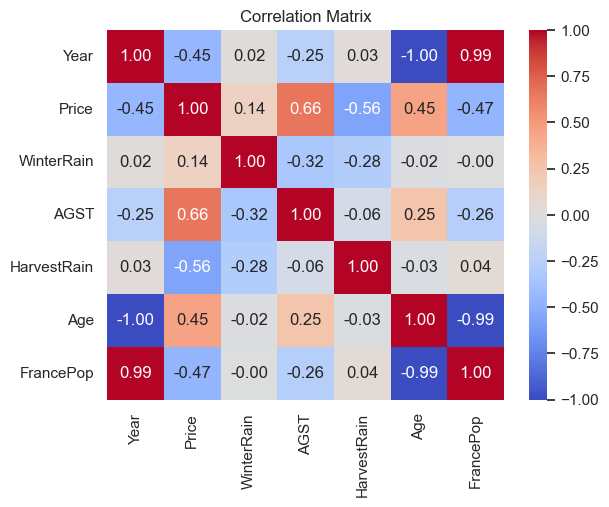

In [25]:
# create the correlation matrix
corr = wine_df.corr()

# Show the correlation matirx with a heatmap    
# plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Matrix")     
plt.show()

### Exercise

When building a linear regression model, the goal is to create a model that not only fits the data well but also includes only statistically significant variables. To achieve this, follow these steps:

1. Start with all potential predictor variables in your model.


2. Examine the p-values associated with each variable. A p-value less than the chosen significance level (e.g., 0.05) indicates that the variable is statistically significant and should be kept in the model.

3. Remove the variable with the highest p-value above the significance level. This variable is the least statistically significant.

4. Rerun the model with the remaining variables and repeat steps 2-3 until all variables in the model are statistically significant.

5. Check the R-squared (R2) value of your final model. R2 measures the proportion of variance in the dependent variable that is predictable from the independent variable(s). A higher R2 indicates a better fit, with a maximum value of 1.


It's important to note that removing a non-statistically significant variable may cause a slight decrease in R2. However, it is generally better to have a model with only statistically significant variables, as this ensures that each variable contributes meaningfully to the model's predictions.

Additionally, before building your model, check for multicollinearity among your predictor variables. Multicollinearity occurs when two or more predictor variables are highly correlated with each other. This can lead to unstable coefficient estimates and difficulty in interpreting the individual effects of predictor variables on the dependent variable.

To detect multicollinearity, calculate the correlation matrix of your predictor variables. If any pair of variables has a correlation coefficient close to +1 or -1 (e.g., greater than 0.8 or less than -0.8), consider removing one of the variables from your model.

In [26]:
#add more variables by modifying the regression formula
model_all=smf.ols('Price ~ HarvestRain + Age', data = wine_df)
result_all=model_all.fit()
print(result_all.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.504
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     11.18
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           0.000446
Time:                        09:08:21   Log-Likelihood:                -15.440
No. Observations:                  25   AIC:                             36.88
Df Residuals:                      22   BIC:                             40.54
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       7.1541      0.312     22.939      

After checking the combinations of variables ($R^2$, Adjusted $R^2$), significance, and multicollinearity, we found our best model consists of variables AGST, HarvestRain, WinterRain, and ? .

In [27]:
model_best = smf.ols('Price ~ AGST + HarvestRain  + WinterRain + Age', data = wine_df)
result_best = model_best.fit()
print(result_best.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.794
Method:                 Least Squares   F-statistic:                     24.17
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           2.04e-07
Time:                        09:08:21   Log-Likelihood:                -2.1622
No. Observations:                  25   AIC:                             14.32
Df Residuals:                      20   BIC:                             20.42
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -3.4300      1.766     -1.942      

### Predicting using the test set


In [28]:
test_path = r"C:\Users\moeka\Downloads\WineTest.csv" #Replace by your file path
wine_test = pd.read_csv(test_path)

wine_test.head()

,Year,Price,WinterRain,AGST,HarvestRain,Age,FrancePop
0,1979,6.9541,717,16.1667,122,4,54835.832
1,1980,6.4979,578,16.0000,74,3,55110.236


In [29]:
# Predict with the best model
y_pred = result_best.predict(wine_test)

print(y_pred)

0    6.768925
1    6.684910
dtype: float64


### Calculting the out-of-sample $R^2$



We calculate the mean (naïve) price on the TRAINING data. Notice although we compute the score out of sample (test data), we still use the mean of the training data.

The reason for this is that when we evaluate our model's performance on the test set, we want to compare it to the baseline model that was developed using only the training data. If we used the mean of the test set, we would be introducing information from the test set into our baseline model, which would lead to an overly optimistic estimate of the model's performance.


In [30]:
y_true = wine_test["Price"]

#y_mean = np.mean(y_true)
y_mean = np.mean(wine_df["Price"])

# Calcualte the SSE
sse = np.sum((y_true - y_pred) ** 2)
print("SSE: ", sse)

# Calcualte the SST
sst = np.sum((y_true - y_mean) ** 2)
print("SST: ", sst)

# Calcualte the R^2
r_squared = 1 - (sse / sst)     
print("R^2: ", r_squared)

SSE:  0.06926280848776223
SST:  0.3369268563519997
R^2:  0.7944277602631924


## Linear regression with sklearn


### Installation notes (optional)

If you have not installed sklearn, it is recommended to install it in a separate environement. 

Using an isolated environment such as pip venv or conda makes it possible to install a specific version of scikit-learn with pip or conda and its dependencies independently of any previously installed Python packages.

    * open anaconda prompt
    * conda create -n sklearn-env -c conda-forge scikit-learn 
    * conda activate sklearn-env

I wanted to first clone my mfbase env
    * conda create -n sklearn-env --clone mfbase
    * conda activate sklearn-env
    * conda install -c conda-forge scikit-learn
    
Note that you should always remember to activate the environment of your choice prior to running any Python command whenever you start a new terminal session. (conda activate NAME)


**STEP 1:  Import the Required Libraries**

In [31]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

**STEP 2:  Prepare the data**

    - Example Data (X = features, y = target)
    - Split into Training and Test Sets

In [32]:
data_path = r"C:\Users\moeka\Downloads\Wine.csv"
wine_df = pd.read_csv(data_path)
wine_df.head()
#wine_df.info()  

# Define the features and target variable
X = wine_df[['Year', 'WinterRain', 'AGST', 'HarvestRain', 'Age', 'FrancePop']]
y = wine_df['Price']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape: ", X_train.shape)
print("X_test shape: ", X_test.shape)

X_train shape:  (20, 6)
X_test shape:  (5, 6)


In [33]:
#On larger datasets, we usually split our data into three sets: training, validation, and test. 
#In this case, we can split first into a training set and a remaining set, and then split the remaining set into validation and test

#Split into train (15) and remaining (10)
#train_df, val_test_df = train_test_split(wine_df, train_size=15, random_state=42)

#Split remainder into validation (6) and test (4)
#valid_df, test_df = train_test_split(val_test_df, train_size=6, random_state=42)

#print("Train set:", train_df.shape[0])
#print("Validation set:", valid_df.shape[0])
#print("Test set:", test_df.shape[0])

**STEP 3:  Create and Train the Model**

In [34]:
# Create a linear model
model = LinearRegression()
# Fit the model to the training data
result = model.fit(X_train, y_train)

**STEP 4:  Make prediction**

In [35]:
y_pred = result.predict(X_test)  # Predict on test data

**STEP 5:  Evaluate the model**

In [36]:
print("Regression coefficients: ", result.coef_)
print("Regression intercept: ", result.intercept_)
print("R² Score:", r2_score(y_test, y_pred))  # Goodness of fit
print("MSE:", mean_squared_error(y_test, y_pred))  # Mean squared error
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))  # Root mean squared error

# Create a DataFrame to compare actual vs predicted values      
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(comparison_df.head())  # Display the first 5 rows of the comparison DataFrame

Regression coefficients:  [ 4.27528853e-02  1.25762480e-03  5.99778005e-01 -4.48681053e-03
 -4.27528853e-02 -2.24624986e-04]
Regression intercept:  -75.06360651897067
R² Score: 0.5271284390839113
MSE: 0.17505029659716537
RMSE: 0.4183901248800757
    Actual  Predicted
8   7.3880   7.537458
16  7.5883   7.320859
0   7.4950   7.667483
23  6.2587   6.976270
11  6.2518   5.765248


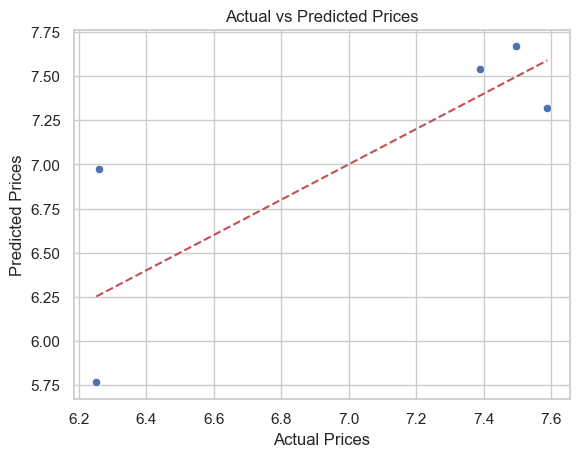

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a scatter plot of actual vs predicted values with seaborn
sns.scatterplot(data=comparison_df, x='Actual', y='Predicted')  
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Prices') 
plt.ylabel('Predicted Prices')
 # Add a reference line (y = x)
plt.plot([comparison_df['Actual'].min(), comparison_df['Actual'].max()], 
         [comparison_df['Actual'].min(), comparison_df['Actual'].max()], 
         'r--') 
plt.show()

In summary:

    . Use **scikit-learn** for prediction and machine learning pipelines.
    . Use **statsmodels** for statistical inference (p-values, CI, hypothesis testing).
    

## Variable selection with MLxtend package

    * The motivation behind feature selection algorithms is to automatically select a subset of features most relevant to the problem. 
    * Sequential feature selection algorithms are a family of greedy search algorithms that are used to reduce an initial d-dimensional feature space to a k-dimensional feature subspace where `k < d`. 
    * In a nutshell, SFAs remove or add one feature at a time based on the classifier performance until a feature subset of the desired size k is reached. 
    * The floating variants, SFFS and SBFS, can be considered extensions to the simpler SFS and SBS algorithms. The floating algorithms have an additional exclusion or inclusion step to remove features once they were included (or excluded) so that a larger number of feature subset combinations can be sampled.

In [38]:
# Import the necessary libraries
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.linear_model import LinearRegression   
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [39]:
# Prepare the data
data_path = r"C:\Users\moeka\Downloads\wine.csv"
wine_df = pd.read_csv(data_path)
wine_df.head()

X = wine_df.drop(columns=["Price"])  # Features
y = wine_df["Price"]  # Target variable

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape: ", X_train.shape) 
print("X_test shape: ", X_test.shape)

X_train shape:  (20, 6)
X_test shape:  (5, 6)


In [40]:
# Create a linear regression model
lr = LinearRegression()

### Backward variable selection

In [41]:
# Perform backward variable selection with the mlxtend package
sbs = SFS(lr,   
          k_features=3, 
          forward=False, 
          floating=False, 
          verbose=0,
          scoring='neg_mean_squared_error', # r2
          cv=4)

# Fit the model
sbs = sbs.fit(X_train, y_train)
#sbs.subsets_
sbs_df = pd.DataFrame.from_dict(sbs.get_metric_dict()).T
sbs_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
6,"(0, 1, 2, 3, 4, 5)","[-0.258504487944404, -0.23599571281567977, -0....",-0.218103,"(Year, WinterRain, AGST, HarvestRain, Age, Fra...",0.058453,0.036465,0.021053
5,"(0, 1, 2, 3, 4)","[-0.2598949350255234, -0.03292311502272436, -0...",-0.191893,"(Year, WinterRain, AGST, HarvestRain, Age)",0.14942,0.093214,0.053817
4,"(0, 1, 2, 3)","[-0.25989493502552063, -0.032923115022729516, ...",-0.191893,"(Year, WinterRain, AGST, HarvestRain)",0.14942,0.093214,0.053817
3,"(1, 2, 3)","[-0.2593265084763738, -0.061716148260206403, -...",-0.199019,"(WinterRain, AGST, HarvestRain)",0.223985,0.13973,0.080673


### Forward variable selection

In [42]:
# Perform forward variable selection
sfs = SFS(lr,   
          k_features=3, 
          forward=True, 
          floating=False, 
          verbose=0,
          scoring='neg_mean_squared_error', # r2
          cv=4)
# Fit the model
sfs = sfs.fit(X_train, y_train)
#sfs.subsets_  
# print the selected features names
print("Selected features: ", sfs.k_feature_names_)  

sfs_df = pd.DataFrame.from_dict(sfs.get_metric_dict()).T
sfs_df

Selected features:  ('AGST', 'HarvestRain', 'FrancePop')


,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
1,"(2,)","[-0.2919154374391494, -0.22804479250604986, -0...",-0.285988,"(AGST,)",0.177574,0.110777,0.063957
2,"(2, 3)","[-0.20661862805248657, -0.05100161593816845, -...",-0.184407,"(AGST, HarvestRain)",0.237304,0.148039,0.08547
3,"(2, 3, 5)","[-0.15133233308890154, -0.1356000671151221, -0...",-0.190939,"(AGST, HarvestRain, FrancePop)",0.100899,0.062944,0.036341


### Stepwise selection 

In [43]:
# Perform backward with floating variable selection
sbfs = SFS(lr,   
           k_features=3, 
           forward=False, 
           floating=True, 
           verbose=0,
           scoring='neg_mean_squared_error', # r2
           cv=4) 

sbfs = sbfs.fit(X_train, y_train)
#sbfs.subsets_
# print the selected features names
print("Selected features: ", sbfs.k_feature_names_)
# visualize the results in a DataFrame
sbfs_df = pd.DataFrame.from_dict(sbfs.get_metric_dict()).T
sbfs_df

Selected features:  ('AGST', 'HarvestRain', 'FrancePop')


,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
6,"(0, 1, 2, 3, 4, 5)","[-0.258504487944404, -0.23599571281567977, -0....",-0.218103,"(Year, WinterRain, AGST, HarvestRain, Age, Fra...",0.058453,0.036465,0.021053
5,"(0, 1, 2, 3, 4)","[-0.2598949350255234, -0.03292311502272436, -0...",-0.191893,"(Year, WinterRain, AGST, HarvestRain, Age)",0.14942,0.093214,0.053817
4,"(1, 2, 3, 5)","[-0.23972901488064732, -0.04556332002314364, -...",-0.170872,"(WinterRain, AGST, HarvestRain, FrancePop)",0.119148,0.074329,0.042914
3,"(2, 3, 5)","[-0.15133233308890154, -0.1356000671151221, -0...",-0.190939,"(AGST, HarvestRain, FrancePop)",0.100899,0.062944,0.036341


In [44]:

# Perform forward with floating variable selection
sffs = SFS(lr,   
           k_features=3, 
           forward=True, 
           floating=True, 
           verbose=0,
           scoring='r2',
           cv=4)
sffs = sffs.fit(X_train, y_train)
#sffs.subsets_
# print the selected features names
print("Selected features: ", sffs.k_feature_names_)
sffs_df = pd.DataFrame.from_dict(sffs.get_metric_dict()).T
sffs_df

Selected features:  ('WinterRain', 'AGST', 'HarvestRain')


,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
1,"(2,)","[0.15157017286550856, 0.21048427092526523, 0.2...",0.236227,"(AGST,)",0.094576,0.059,0.034064
2,"(2, 3)","[0.39947880653663936, 0.8234268910554297, 0.72...",0.577615,"(AGST, HarvestRain)",0.32391,0.202067,0.116664
3,"(1, 2, 3)","[0.24628739511638564, 0.7863320216441749, 0.67...",0.522801,"(WinterRain, AGST, HarvestRain)",0.34673,0.216303,0.124883


### Ploting the results

Selected features:  ('WinterRain', 'AGST', 'HarvestRain', 'FrancePop')


[Parallel(n_jobs=1)]: Done   6 out of   6 | elapsed:    0.0s finished

[2026-09-30 09:08:22] Features: 1/6 -- score: -0.32019282315824316[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.0s finished

[2026-09-30 09:08:22] Features: 2/6 -- score: -0.22652386572704306[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s finished

[2026-09-30 09:08:22] Features: 3/6 -- score: -0.15808068255127639[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s finished

[2026-09-30 09:08:22] Features: 4/6 -- score: -0.1443419135921181[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s finished

[2026-09-30 09:08:22] Features: 5/6 -- score: -0.1583382771571079[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished

[2026-09-30 09:08:22] Features: 6/6 -- score: -0.15833827715717863

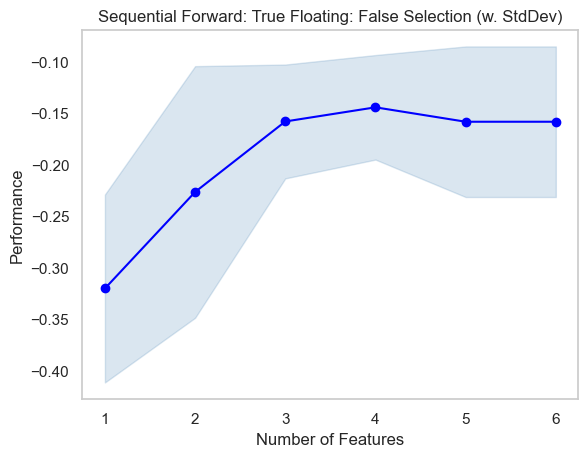

In [45]:
# ploting the results of the forward variable selection
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt

forward_var = True
floating_var = False
sfs = SFS(lr, 
          k_features=(1, 6), 
          forward=forward_var, 
          floating=floating_var, 
          scoring='neg_mean_squared_error', # r2
          verbose=2,
          cv=3)

sfs = sfs.fit(X_train, y_train)
# get the selected features names
print("Selected features: ", sfs.k_feature_names_)

# plot the results
fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_dev')
plt.title(f'Sequential Forward: {forward_var} Floating: {floating_var} Selection (w. StdDev)')
plt.grid()
plt.show()

### Using the Selected Feature Subset For Making New Predictions


In [46]:
# Generate the new subsets based on the selected features
# Note that the transform call is equivalent to
# X_train[:, sfs.k_feature_names_]
X_train_sfs = sfs.transform(X_train)
X_test_sfs = sfs.transform(X_test)


# Fit the model with the selected features
lr = LinearRegression()
lr.fit(X_train_sfs, y_train)

# Predict on the test set
y_pred = lr.predict(X_test_sfs)

# Evaluate the model
print("R² Score:", r2_score(y_test, y_pred))  # Goodness of fit
print("MSE:", mean_squared_error(y_test, y_pred))  # Mean squared error
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))  # Root mean squared error

R² Score: 0.6463791447948545
MSE: 0.13090538891085574
RMSE: 0.3618084975658473
